In [21]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter
from PIL import Image
from PIL.ExifTags import TAGS


plt.rc("font", size=12)
plt.rc("grid", linestyle="--", color="lightgray")
plt.rc("axes.spines", right=False, top=False)
pv.set_jupyter_backend("static")

datadir = Path("../../data/")


COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}

In [22]:
"""Combine a microscopy volume overview with a local STORM point-cloud view.

Use the existing grid and the already converted/re-zeroed Polars dataframe:

    xyz = df.select(["x", "y", "z"]).to_numpy()
    rendered = render_volume_storm(grid, xyz)
    fig, (overview_ax, storm_ax) = compose_volume_storm(rendered)
    # Save with your existing save_panel(fig, stem) helper.

No transposition, unit conversion or registration is performed here. The grid
retains its existing spacing/orientation; STORM coordinates retain their local
origin. The overview ROI is a vector annotation, not an inferred registration.

Requirements: numpy, matplotlib, pyvista, and a working VTK rendering backend.
"""

@dataclass(frozen=True)
class RenderedView:
    image: np.ndarray
    extent: tuple  # xmin, xmax, ymin, ymax in this panel's own coordinates.
    image_extent: tuple  # Camera coverage accounting for integer pixel sizes.


def _capture_xy(p, data_bounds, xy_bounds, height_px):
    """Capture a tight XY view, with no labels or ROI in the raster image."""
    bounds = np.asarray(data_bounds, dtype=float)
    extent = np.asarray(bounds[:4] if xy_bounds is None else xy_bounds, dtype=float)
    if extent.shape != (4,) or not np.all(np.isfinite(extent)):
        raise ValueError("XY bounds must contain four finite coordinates.")
    x0, x1, y0, y1 = extent
    dx, dy = x1 - x0, y1 - y0
    if dx <= 0 or dy <= 0:
        raise ValueError("Each view needs increasing X and Y bounds.")
    # ceil() retains the complete requested width, adding less than one pixel.
    width_px = max(2, int(np.ceil(height_px * dx / dy)))
    p.window_size = (width_px, height_px)
    cx, cy, cz = (x0 + x1) / 2, (y0 + y1) / 2, (bounds[4] + bounds[5]) / 2
    distance = 2 * max(dx, dy, bounds[5] - bounds[4])
    p.set_background("black")
    p.enable_parallel_projection()
    p.camera_position = [(cx, cy, cz + distance), (cx, cy, cz), (0, 1, 0)]
    p.camera.parallel_scale = dy / 2
    p.reset_camera_clipping_range()
    half_width = (dy / 2) * width_px / height_px
    image_extent = (cx - half_width, cx + half_width, y0, y1)
    p.render()
    image = np.array(p.screenshot(transparent_background=False), copy=True)
    return RenderedView(image, tuple(extent), image_extent)


def render_volume_storm(
    grid,
    xyz,
    *,
    height_px=700,
    overview_bounds=None,
    storm_bounds=None,
    scalars="desmin",
    color="#FF0000",
    volume_clim=(0, 300),
    volume_opacity=(0.0, 0.1, 0.8),
    point_size=1.0,
    point_opacity=0.4,
):
    """Render the overview volume and STORM points using the supplied settings.

    xyz must be an N-by-3 array already in micrometres, with the desired local
    origin. The points are projected onto Z=0, matching the original code.
    The input array and grid are not modified. The volume uses maximum blending
    and linear interpolation; the cloud uses style="points_gaussian".

    By default, bounds come from the actual grid and projected cloud, not from
    rounded screenshot labels. Each optional bound is (xmin, xmax, ymin, ymax)
    in the corresponding dataset's own coordinate system. These set the camera
    framing without filtering or modifying the underlying coordinates.

    height_px controls the source image resolution in both panels.
    Rendering is separate from composition: font/layout changes need no rerender.
    """
    import pyvista as pv

    height_px = int(height_px)
    if height_px < 2:
        raise ValueError("height_px must be at least 2.")
    xyz = np.asarray(xyz, dtype=float)
    if xyz.ndim != 2 or xyz.shape[1] != 3 or xyz.shape[0] == 0:
        raise ValueError("xyz must be a nonempty N-by-3 array.")
    if not np.all(np.isfinite(xyz)):
        raise ValueError("xyz contains non-finite coordinates.")

    p = pv.Plotter(off_screen=True, window_size=(height_px, height_px))
    try:
        actor = p.add_volume(
            grid, scalars=scalars, cmap=[color], opacity=list(volume_opacity),
            clim=volume_clim, blending="maximum", show_scalar_bar=False,
        )
        actor.prop.interpolation_type = "linear"
        overview = _capture_xy(p, grid.bounds, overview_bounds, height_px)
    finally:
        p.close()

    point_cloud = pv.PolyData(xyz).project_points_to_plane(
        origin=(0, 0, 0), normal=(0, 0, 1), inplace=False,
    )
    p = pv.Plotter(off_screen=True, window_size=(height_px, height_px))
    try:
        p.add_mesh(
            point_cloud, color=color, style="points_gaussian",
            point_size=point_size, opacity=point_opacity,
        )
        storm = _capture_xy(p, point_cloud.bounds, storm_bounds, height_px)
    finally:
        p.close()
    return overview, storm


def compose_volume_storm(
    rendered,
    *,
    roi=(120.0, 48.0, 19.0, 19.0),
    panel_height=2.8,
    panel_gap=0.65,
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=10,
    ytick_fontsize=10,
    xtick_pad=7,
    ytick_pad=10,
    xlabel_pad=7,
    ylabel_pad=10,
    ytick_rotation=90,
    tick_format="%.1f",
    xticks=None,
    yticks=None,
    font_family="DejaVu Sans",
    roi_linewidth=0.8,
):
    """Compose equal-height panels with independent axes and common X/Y titles.

    Panel widths follow their physical aspect ratios. Both show their own X/Y
    tick values; the two views have different scales and origins, so axes are
    not linked. All X labels are centred. Lowest Y labels extend upward to
    avoid corner collisions. The ROI rectangle is drawn on the overview only.

    roi is (left, bottom, width, height) in OVERVIEW coordinates; None hides it.
    panel_height/panel_gap are inches. Font sizes, padding and line widths are
    points. Decrease xlabel_pad to bring x (µm) closer to the tick labels.
    xticks/yticks can each be (overview_ticks, storm_ticks), with a None entry
    selecting five equally spaced ticks from that view's actual bounds.
    """
    if len(rendered) != 2:
        raise ValueError("Exactly two rendered views are required.")
    if panel_height <= 0 or panel_gap < 0:
        raise ValueError("Use a positive panel height and nonnegative gap.")
    xchoices = (None, None) if xticks is None else xticks
    ychoices = (None, None) if yticks is None else yticks
    if len(xchoices) != 2 or len(ychoices) != 2:
        raise ValueError("xticks and yticks need two per-panel entries.")
    widths = [panel_height * (v.extent[1] - v.extent[0]) / (v.extent[3] - v.extent[2]) for v in rendered]
    left = max(0.75, (ytick_pad + ylabel_pad + 1.3 * (ytick_fontsize + ylabel_fontsize) + 8) / 72)
    bottom = max(0.65, (xtick_pad + xlabel_pad + 1.3 * (xtick_fontsize + xlabel_fontsize) + 8) / 72)
    top, right = 0.25, 0.30
    total_width = sum(widths) + panel_gap
    fw, fh = left + total_width + right, bottom + panel_height + top

    with mpl.rc_context({"font.family": font_family}):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        axes = []
        xpos = left
        for i, (view, width) in enumerate(zip(rendered, widths)):
            x0, x1, y0, y1 = view.extent
            ax = fig.add_axes([xpos / fw, bottom / fh, width / fw, panel_height / fh], facecolor="black")
            ax.imshow(view.image, extent=view.image_extent, origin="upper", aspect="equal", interpolation="none")
            ax.set_xticks(np.linspace(x0, x1, 5) if xchoices[i] is None else xchoices[i])
            ax.set_yticks(np.linspace(y0, y1, 5) if ychoices[i] is None else ychoices[i])
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
            ax.set_autoscale_on(False)
            ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.tick_params(colors="white", direction="in", length=3, width=0.7)
            ax.tick_params(axis="x", labelsize=xtick_fontsize, pad=xtick_pad)
            ax.tick_params(axis="y", labelsize=ytick_fontsize, pad=ytick_pad, labelrotation=ytick_rotation)
            for side, spine in ax.spines.items():
                spine.set_visible(side in ("left", "bottom"))
                spine.set_color("white")
                spine.set_linewidth(0.7)
            for label in ax.get_xticklabels():
                label.set_ha("center")
            for value, label in zip(ax.get_yticks(), ax.get_yticklabels()):
                label.set_va("bottom" if np.isclose(value, y0) else "center")
            axes.append(ax)
            xpos += width + panel_gap

        if roi is not None:
            rx, ry, rw, rh = roi
            axes[0].add_patch(Rectangle(
                (rx, ry), rw, rh, fill=False, edgecolor="white",
                linewidth=roi_linewidth, clip_on=False, zorder=5,
            ))
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        xboxes = [t.get_window_extent(renderer) for ax in axes for t in ax.get_xticklabels() if t.get_visible()]
        yboxes = [t.get_window_extent(renderer) for t in axes[0].get_yticklabels() if t.get_visible()]
        inverse = fig.transFigure.inverted()
        xlabel_y = inverse.transform((0, min(b.y0 for b in xboxes)))[1] - xlabel_pad / (72 * fh)
        ylabel_x = inverse.transform((min(b.x0 for b in yboxes), 0))[0] - ylabel_pad / (72 * fw)
        fig.supxlabel("x (µm)", x=(left + total_width / 2) / fw, y=xlabel_y, va="top", color="white", fontsize=xlabel_fontsize)
        fig.supylabel("y (µm)", x=ylabel_x, y=(bottom + panel_height / 2) / fh, ha="right", color="white", fontsize=ylabel_fontsize)
    return fig, tuple(axes)

def parse_exif_data(exif_data):
    exif_dict = dict()
    for tag_id in exif_data:
        tag = TAGS.get(tag_id, tag_id)
        content = exif_data.get(tag_id)
        exif_dict[tag] = content
    return exif_dict

In [23]:
img = Image.open(datadir / "STORM/desmin_260nm/2016-12-19-10-33-07_probe0.tif")

In [24]:
metadata = parse_exif_data(img.getexif())
print(metadata)

{'ImageWidth': 2048, 'ImageLength': 2048, 'BitsPerSample': 16, 'Compression': 1, 'PhotometricInterpretation': 1, 50839: b'IJIJover\x00\x00\x00\x02Iout\x00\xe4\x01\x00\x07\xc3\x07W\x07\xc7\x07\xd8\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xff\xff\xff\xff\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00@\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x80\x00\x00\x00\x04\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00|\x00S\x00B\x00|Iout\x00\xe4\x01\x00\x07\xc7\x07|\x07\xdc\x07\xb4\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xff\xff\xff\xff\x00\x00\x00\x00\x00\x01\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00v\x00\x00\x00\x0e\x00\x00\x00\x01\x00\x00\x00\x08\x00\x00\x00\t\x00S\x00a\x00n\x00S\x00e\x00r\x00i\x00f

In [25]:
img_data = np.array(img)

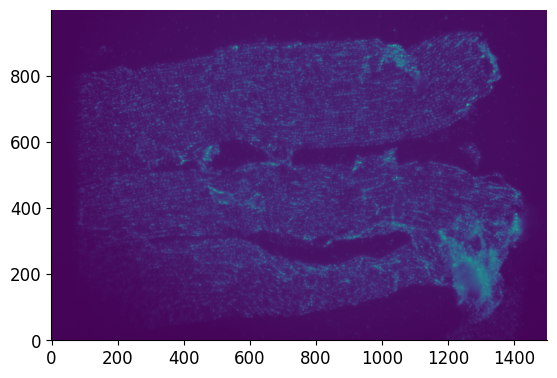

In [26]:
import matplotlib.pyplot as plt


plt.imshow(img_data[350:1350, 200:1700], origin="lower")

In [27]:
img_data_roi = img_data[350:1350, 200:1700].T
img_data_roi = img_data_roi[:, ::-1]

In [28]:
grid_shape = np.asarray(img_data_roi.shape + (1,)) + 1
pixel_sizes = (
    1e-3 / metadata["YResolution"],
    1e-3 / metadata["XResolution"],
    1e-3 / metadata["XResolution"],
)

grid = pv.ImageData(dimensions=grid_shape, spacing=pixel_sizes)
grid.cell_data["desmin"] = img_data_roi.flatten(order="F")

In [29]:
# filepath = datadir / "STORM/desmin_260nm/2016-12-19-11-12-35.csv"
filepath = datadir / "STORM/desmin_260nm/2016-12-19-10-33-07.csv"
df = pl.read_csv(filepath)
df = df.with_columns(*[pl.col(i) / 1000 for i in ("x", "y", "z")])
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])
df.head()

image-ID,time-point,cycle,z-step,frame,accum,probe,photon-count,photon-count11,photon-count12,photon-count21,photon-count22,psfx,psfy,psfz,psf-photon-count,x,y,z,stdev,amp,background11,background12,background21,background22,maxResidualSlope,chisq,log-likelihood,llr,accuracy,fiducial,valid,precisionx,precisiony,precisionz,cluster-ID,particle-ID
i64,i64,i64,i64,i64,i64,i64,f64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,i64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64
0,0,0,0,0,1,0,1252.68,0,0,0,0,21.2169,55.3532,19.2242,1035.79,9.859219,13.951713,0.292219,0,35.609,26.4716,30.7773,0,0,0,122.09,-829.852,0,0,0,1,0,0,0,0,-1
0,0,0,0,0,1,0,1226.47,0,0,0,0,12.2247,133.875,-169.344,839.349,6.280419,16.763313,0.480787,0,28.9534,23.8035,29.2058,0,0,0,158.866,-837.312,0,0,0,1,0,0,0,0,-1
0,0,0,0,0,1,0,1234.34,0,0,0,0,29.1229,61.5517,55.7145,1123.86,7.160459,15.041813,0.255728,0,38.7211,26.8101,31.7938,0,0,0,72.8863,-806.555,0,0,0,1,0,0,0,0,-1
0,0,0,0,0,1,0,1634.57,0,0,0,0,1.06623,96.2198,127.393,1721.82,1.408229,10.921113,0.18405,0,60.1023,23.8562,27.8991,0,0,0,90.5522,-806.868,0,0,0,1,0,0,0,0,-1
0,0,0,0,0,1,0,1125.32,0,0,0,0,178.39,-72.5006,-114.773,834.286,18.771119,7.502033,0.426216,0,29.4252,25.8965,30.2114,0,0,0,62.8884,-790.633,0,0,0,1,0,0,0,0,-1


In [30]:
coords = df.select(["x", "y", "z"]).to_numpy()

In [31]:
rendered = render_volume_storm(
    grid,
    coords,
    height_px=1800,
    volume_clim=(0, 300),
    volume_opacity=(0.0, 0.1, 1.0),
    color = COLOR_DICT["desmin"],
    point_size=1.0,
    point_opacity=0.4,
)


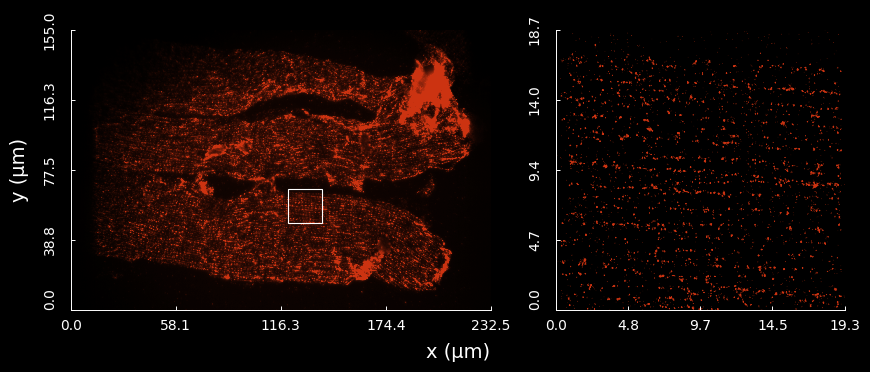

In [32]:
fig, (overview_ax, storm_ax) = compose_volume_storm(
    rendered,
    roi=(120, 48, 19, 19),  # Left, bottom, width, height
    panel_height=2.8,      # Inches
    panel_gap=0.65,        # Gap between panels, inches

    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=10,
    ytick_fontsize=10,

    xtick_pad=7,           # Tick-label padding, points
    ytick_pad=10,
    xlabel_pad=7,          # Common axis-title padding, points
    ylabel_pad=10,

    ytick_rotation=90,
    tick_format="%.1f",
    roi_linewidth=0.8,
)

In [33]:
savepath = "../../figures/1c"
save_panel(fig, savepath, formats=("svg",))

[PosixPath('../../figures/1c.svg')]

In [34]:
display(SVG(filename=str(savepath+".svg")))
plt.close(fig)